<a href="https://colab.research.google.com/github/240264-sudo/AI-ML-lab/blob/main/AI_ML_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, r2_score, mean_squared_error, mean_absolute_error

# 1. Download and Load Dataset
path = kagglehub.dataset_download("laxmikantaroy/lung-cancer-risk-factors-and-survival-dataset")
print("Path to dataset files:", path)

csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
if not csv_files:
    raise FileNotFoundError("No CSV file found in the downloaded dataset directory.")

df_path = os.path.join(path, csv_files[0])
df_raw = pd.read_csv(df_path)
print(f"\nDataset loaded successfully. Shape: {df_raw.shape}")

# -----------------------------------------------------
# PART 1: LOGISTIC REGRESSION (Target: 'Survived')
# -----------------------------------------------------
print("\n--- Running Logistic Regression (Classification) ---")

# Preprocessing
cols_to_drop_clf = [col for col in df_raw.columns if 'id' in col.lower() or 'date' in col.lower()]
df_clf = df_raw.drop(columns=cols_to_drop_clf, errors='ignore').dropna()

# Encode categorical variables
le = LabelEncoder()
for col in df_clf.select_dtypes(include=['object', 'category']).columns:
    df_clf[col] = le.fit_transform(df_clf[col])

# Split features and target
X_clf = df_clf.drop(columns=['Survived'])
y_clf = df_clf['Survived']

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

# Scale features
scaler_clf = StandardScaler()
X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_clf_scaled = scaler_clf.transform(X_test_clf)

# Train and Predict
clf_model = LogisticRegression(max_iter=1000)
clf_model.fit(X_train_clf_scaled, y_train_clf)
y_pred_clf = clf_model.predict(X_test_clf_scaled)

# Output Metrics
print("Accuracy:", accuracy_score(y_test_clf, y_pred_clf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test_clf, y_pred_clf))
print("\nClassification Report:\n", classification_report(y_test_clf, y_pred_clf))

# -----------------------------------------------------
# PART 2: LINEAR REGRESSION (Target: 'Survival_Months')
# -----------------------------------------------------
print("\n--- Running Linear Regression (Regression) ---")

# Preprocessing
cols_to_drop_reg = [col for col in df_raw.columns if 'id' in col.lower() or 'date' in col.lower() or col == 'Survived']
df_reg = df_raw.drop(columns=cols_to_drop_reg, errors='ignore').dropna()

# Encode categorical variables
for col in df_reg.select_dtypes(include=['object', 'category']).columns:
    df_reg[col] = LabelEncoder().fit_transform(df_reg[col])

# Split features and target
X_reg = df_reg.drop(columns=['Survival_Months'])
y_reg = df_reg['Survival_Months']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Scale features
scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

# Train and Predict
reg_model = LinearRegression()
reg_model.fit(X_train_reg_scaled, y_train_reg)
y_pred_reg = reg_model.predict(X_test_reg_scaled)

# Output Metrics
print(f"R-squared (R2) Score : {r2_score(y_test_reg, y_pred_reg):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test_reg, y_pred_reg):.4f}")
print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_test_reg, y_pred_reg):.4f}")

Using Colab cache for faster access to the 'lung-cancer-risk-factors-and-survival-dataset' dataset.
Path to dataset files: /kaggle/input/lung-cancer-risk-factors-and-survival-dataset

Dataset loaded successfully. Shape: (2000, 46)

--- Running Logistic Regression (Classification) ---
Accuracy: 0.7025

Confusion Matrix:
 [[186  63]
 [ 56  95]]

Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.75      0.76       249
           1       0.60      0.63      0.61       151

    accuracy                           0.70       400
   macro avg       0.68      0.69      0.69       400
weighted avg       0.71      0.70      0.70       400


--- Running Linear Regression (Regression) ---
R-squared (R2) Score : 0.7231
Mean Squared Error (MSE): 138.9665
Mean Absolute Error (MAE): 8.8022


=== PREDICTION RESULTS ===
Predicted Survival Status: No (Did not survive)
Confidence: 59.70%


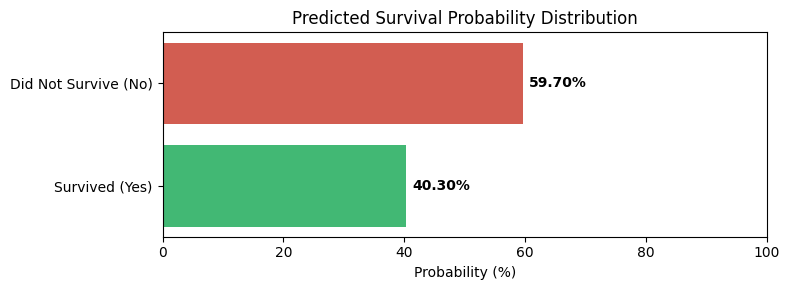

In [ ]:
#@title Logistic Regression Predictor with Probability Visualization
#@markdown Enter patient details below to predict survival status (Yes/No):

# Get user input through Colab Form
Age = 30 #@param {type:"slider", min:1, max:100, step:1}
Cigarettes_Per_Day = 15 #@param {type:"integer"}
Tumor_Size_cm = 5.2 #@param {type:"number"}
Symptom_Count = 2 #@param {type:"slider", min:0, max:10, step:1}

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Retrieve model features and structure from our trained logistic regression pipeline
# To prevent scaling distortions, we initialize the patient profile using dataset medians
input_dict = {}
for col in X_train_clf.columns:
    # Use median values for numerical columns to ensure realistic data representation
    input_dict[col] = X_train_clf[col].median()

# Override with user specified inputs from the form
if 'Age' in input_dict: input_dict['Age'] = Age
if 'Cigarettes_Per_Day' in input_dict: input_dict['Cigarettes_Per_Day'] = Cigarettes_Per_Day
if 'Tumor_Size_cm' in input_dict: input_dict['Tumor_Size_cm'] = Tumor_Size_cm
if 'Symptom_Count' in input_dict: input_dict['Symptom_Count'] = Symptom_Count

# Create DataFrame of single input
input_df = pd.DataFrame([input_dict])

# Scale the user input using the fitted scaler
input_scaled = scaler_clf.transform(input_df)

# Predict prediction probability and class
prediction_prob = clf_model.predict_proba(input_scaled)[0]
prediction_class = clf_model.predict(input_scaled)[0]

# Decode class back to human readable status
survival_status = "Yes (Survived)" if prediction_class == 1 else "No (Did not survive)"

print("=== PREDICTION RESULTS ===")
print(f"Predicted Survival Status: {survival_status}")
print(f"Confidence: {prediction_prob[prediction_class]*100:.2f}%")

# Visualize the classification probabilities
plt.figure(figsize=(8, 3))
categories = ['Did Not Survive (No)', 'Survived (Yes)']
probabilities = [prediction_prob[0] * 100, prediction_prob[1] * 100]
colors = ['#e74c3c', '#2ecc71']

ax = sns.barplot(x=probabilities, y=categories, palette=colors, hue=categories, legend=False)
plt.xlim(0, 100)
plt.title('Predicted Survival Probability Distribution')
plt.xlabel('Probability (%)')

# Add numeric percentages on the bars
for i, p in enumerate(probabilities):
    ax.text(p + 1, i, f"{p:.2f}%", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
#@title Model Weight Diagnostic
# Let's inspect the weights (coefficients) of the logistic regression model
import pandas as pd

coefficients = pd.DataFrame({
    'Feature': X_train_clf.columns,
    'Coefficient (Weight)': clf_model.coef_[0]
})

# Sort by absolute impact
coefficients['Absolute Impact'] = coefficients['Coefficient (Weight)'].abs()
coefficients = coefficients.sort_values(by='Absolute Impact', ascending=False).drop(columns=['Absolute Impact'])

print("=== TOP FEATURE INFLUENCES ===")
print("Positive coefficients increase probability of survival (class 1).")
print("Negative coefficients increase probability of non-survival (class 0).\n")
display(coefficients.head(10))

# Specifically print user-controlled features
print("\n=== USER-CONTROLLED FEATURE WEIGHTS ===")
user_features = ['Age', 'Cigarettes_Per_Day', 'Tumor_Size_cm', 'Symptom_Count']
display(coefficients[coefficients['Feature'].isin(user_features)])

=== TOP FEATURE INFLUENCES ===
Positive coefficients increase probability of survival (class 1).
Negative coefficients increase probability of non-survival (class 0).



,Feature,Coefficient (Weight)
37,Cancer_Stage,-1.325608
22,Risk_Factor_Count,0.514849
6,Smoking_Status,-0.259301
3,Age,0.252682
19,Asbestos_Exposure,-0.242441
18,Chronic_Lung_Disease,-0.205635
11,Family_History,-0.168332
10,Secondhand_Smoke,-0.166936
12,Occupational_Hazard,-0.166273
39,Metastasis,-0.161092



=== USER-CONTROLLED FEATURE WEIGHTS ===


,Feature,Coefficient (Weight)
3,Age,0.252682
38,Tumor_Size_cm,0.076275
7,Cigarettes_Per_Day,-0.048913
34,Symptom_Count,-0.023199


Training Linear Regression model to predict: Survival_Months

--- Regression Model Evaluation (Target: Survival_Months) ---
R-squared (R2) Score : 0.7231
Mean Squared Error (MSE): 138.9665
Mean Absolute Error (MAE): 8.8022


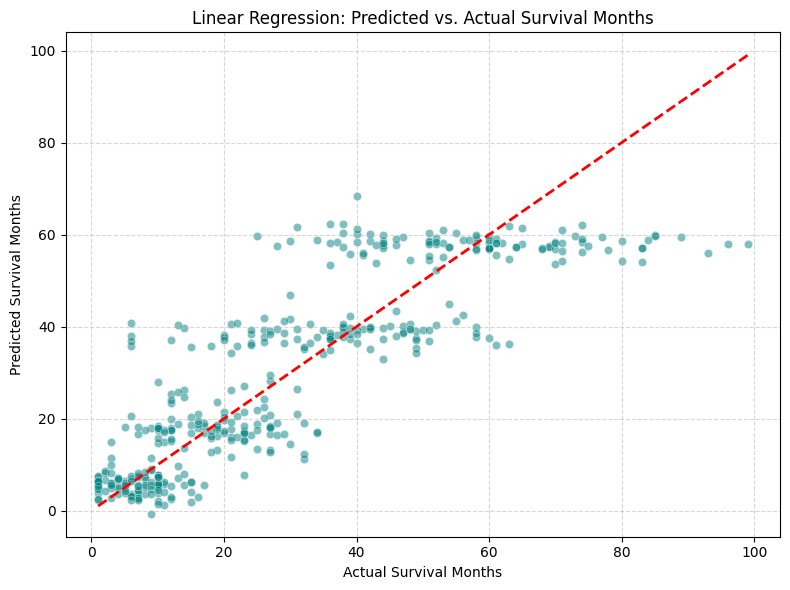

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns

# We will use the preprocessed features from the previous cell, but target a continuous variable instead
# Let's reload and clean the data specifically for a regression task predicting 'Survival_Months'
df_reg = pd.read_csv(df_path)

# Target for regression
reg_target_col = 'Survival_Months'
print(f"Training Linear Regression model to predict: {reg_target_col}")

# Preprocessing
cols_to_drop_reg = [col for col in df_reg.columns if 'id' in col.lower() or 'date' in col.lower() or col == 'Survived']
df_reg = df_reg.drop(columns=cols_to_drop_reg, errors='ignore')
df_reg = df_reg.dropna()

# Encode categorical columns
for col in df_reg.select_dtypes(include=['object', 'category']).columns:
    df_reg[col] = LabelEncoder().fit_transform(df_reg[col])

# Split features and target
X_reg = df_reg.drop(columns=[reg_target_col])
y_reg = df_reg[reg_target_col]

# Train-test split
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Scale features
scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

# Train Linear Regression Model
reg_model = LinearRegression()
reg_model.fit(X_train_reg_scaled, y_train_reg)

# Predict and Evaluate
y_pred_reg = reg_model.predict(X_test_reg_scaled)

# Calculate metrics
r2 = r2_score(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
mae = mean_absolute_error(y_test_reg, y_pred_reg)

print("\n--- Regression Model Evaluation (Target: Survival_Months) ---")
print(f"R-squared (R2) Score : {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

# Visualization of Regression Model Performance (Predicted vs. Actual)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_reg, y=y_pred_reg, alpha=0.5, color='teal')
# Plot perfect prediction line
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
plt.title('Linear Regression: Predicted vs. Actual Survival Months')
plt.xlabel('Actual Survival Months')
plt.ylabel('Predicted Survival Months')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()